# 24 · Classifier, then rerank: a learned stage 1 and a reranker trained on `chat-1`

**Purpose.** Plan `2026-10-18-classifier-then-rerank` (D61): replace X2's hand-set stage 1 with a
logistic classifier trained on the D50 batch (steps 1-2), then train stage-2 rerankers on the
owner's `chat-1` scores of X2's top 100 and ask whether any gets the chat's top 10 into the top 10
better than X2's own order (step 3).

**Status.** Reporting only: every figure is read from `output/matching/stage1-classifier.json` and
`output/rerank/chat-rerank-eval.json`; nothing is fitted here. Bars were fixed in the plan before
the records were built. Steps 1-2 are scored on the human final set (D41). Step 3's target and
reference is `chat-1` (this task only, D61); its human check is **exploratory**. Every CI resamples
JDs (10,000).

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from candidate_screener import reporting
from candidate_screener.config import OUTPUT

reporting.style(plt)
s1 = json.load(open(OUTPUT / "matching" / "stage1-classifier.json"))
s3 = json.load(open(OUTPUT / "rerank" / "chat-rerank-eval.json"))
SCOPES = ("generic", "targeted", "total")
fmt = lambda b: f"{b['value']:+.3f} [{b['ci'][0]:+.3f}, {b['ci'][1]:+.3f}]"
val = lambda b: f"{b['value']:.3f} [{b['ci'][0]:.3f}, {b['ci'][1]:.3f}]"

## 1 · Step 1: the classifier against X2 (final set and final pools)

In [2]:
rows = {}
for arm, b in s1["s1"].items():
    d = {(x["subset"], x["scope"]): x for x in s1["auc_deltas_vs_x2"][b["name"]] if x["metric"] == "auc"}
    r = b["final_pools"]["recall"]
    rows[arm] = {**{f"AUC Δ {sub} {sc}": f"{d[(sub, sc)]['delta']:+.3f} [{d[(sub, sc)]['ci'][0]:+.3f}, {d[(sub, sc)]['ci'][1]:+.3f}]"
                    for sub in ("all", "llm_free") for sc in SCOPES},
                 **{f"recall Δ {sc}": fmt(r[sc]["delta"]) for sc in SCOPES},
                 "passed per JD, median [min, max]": "{median:.0f} [{min}, {max}]".format(**b["final_pools"]["passed_size"]["total"]),
                 "bar (>= -0.06 on both)": b["bar"]["verdict"]}
pd.DataFrame(rows).T.T

,F12,base 4
AUC Δ all generic,"+0.022 [-0.003, +0.047]","-0.004 [-0.016, +0.007]"
AUC Δ all targeted,"-0.016 [-0.055, +0.022]","-0.003 [-0.021, +0.014]"
AUC Δ all total,"+0.009 [-0.013, +0.031]","-0.004 [-0.014, +0.006]"
AUC Δ llm_free generic,"+0.017 [-0.012, +0.045]","-0.001 [-0.018, +0.013]"
AUC Δ llm_free targeted,"-0.027 [-0.132, +0.065]","-0.006 [-0.014, +0.000]"
AUC Δ llm_free total,"+0.003 [-0.035, +0.038]","-0.003 [-0.015, +0.008]"
recall Δ generic,"+0.006 [-0.029, +0.043]","+0.011 [-0.006, +0.032]"
recall Δ targeted,"-0.032 [-0.103, +0.033]","-0.009 [-0.034, +0.013]"
recall Δ total,"-0.007 [-0.040, +0.027]","+0.004 [-0.011, +0.020]"
"passed per JD, median [min, max]","23 [1, 81]","18 [0, 75]"


AUC: mean per-JD AUC, Fit vs No Fit, over JDs with both classes (60). Recall: judged Fits kept by
the passed set, against X2 cut at the same size per JD (59 JDs with a Fit; the 490 unjudged
distractors count as not relevant, so recall is an upper bound).

In [3]:
coef = pd.DataFrame({arm: b["fit"]["standardised"] for arm, b in s1["s1"].items()})
coef.reindex(coef["F12"].abs().sort_values(ascending=False).index).round(3)

,F12,base 4
role_match,1.125,1.257
sbert,0.365,NaN
log_matched,0.351,NaN
tfidf_scaled,0.258,0.383
exp_known,0.172,NaN
experience_compatible,0.170,0.175
coverage,0.143,0.246
log_jd_concepts,-0.125,NaN
skill_overlap,-0.113,NaN
exp_gap,0.108,NaN


## 2 · Step 2: how much of the passed set has a chat score

In [4]:
pd.DataFrame({f"{arm} · {name}": {**{f"overlap {sc}": val(v["overlap"][sc]) for sc in SCOPES},
                                   "CVs with no chat score": v["no_chat_score_per_jd"]["total"],
                                   "judged Fits kept": f"{v['judged_fits_kept']['total']} of {v['judged_fits_kept']['judged_fits']}",
                                   "bar (>= 0.80)": v["verdict"]}
              for arm, b in s1["s2"].items() for name, v in b["shortlists"].items()})

,F12 · passed set,F12 · top 100 by probability,base 4 · passed set,base 4 · top 100 by probability
overlap generic,"0.987 [0.975, 0.996]","0.704 [0.672, 0.738]","1.000 [1.000, 1.000]","0.812 [0.770, 0.852]"
overlap targeted,"0.987 [0.972, 0.998]","0.664 [0.626, 0.703]","1.000 [1.000, 1.000]","0.817 [0.756, 0.866]"
overlap total,"0.987 [0.978, 0.995]","0.691 [0.665, 0.717]","1.000 [1.000, 1.000]","0.814 [0.780, 0.845]"
CVs with no chat score,20,1857,0,1118
judged Fits kept,240 of 367,325 of 367,208 of 367,332 of 367
bar (>= 0.80),pass,fail,pass,pass


## 3 · Step 3: rerankers on X2's top 100, against the chat's top 10

In [5]:
rows = {}
for name, b in s3["candidates"].items():
    if "ablation_of" in b:
        continue
    r = b["summary"]["recall"]
    row = {"R@10 gen / tar": f"{r['generic']['value']:.3f} / {r['targeted']['value']:.3f}",
           "R@10 total": val(r["total"]), "nDCG@10": f"{b['summary']['ndcg']['total']['value']:.3f}",
           "No Fits": f"{b['summary']['no_fits']['total']['value']:.2f}"}
    if b["delta_vs_x2"]:
        d = b["delta_vs_x2"]["recall"]
        row["Δ gen / tar"] = f"{d['generic']['value']:+.3f} / {d['targeted']['value']:+.3f}"
        row["Δ total"] = fmt(d["total"])
        row["bar"] = "pass" if b["passes_bar"] else "fail"
    rows[name[:34]] = row
t3 = pd.DataFrame(rows).T
t3

,R@10 gen / tar,R@10 total,nDCG@10,No Fits,Δ gen / tar,Δ total,bar
extracted rule + TF-IDF,0.421 / 0.416,"0.419 [0.366, 0.471]",0.776,1.70,NaN,NaN,NaN
S1 logistic F12 (D50),0.464 / 0.432,"0.454 [0.403, 0.502]",0.801,1.55,+0.043 / +0.016,"+0.034 [+0.005, +0.063]",fail
"R1 cross-encoder (LLM batch, point",0.230 / 0.113,"0.191 [0.155, 0.227]",0.477,4.85,-0.191 / -0.303,"-0.228 [-0.293, -0.162]",fail
"R2 cross-encoder (LLM batch, pairw",0.269 / 0.162,"0.234 [0.196, 0.273]",0.521,4.32,-0.152 / -0.253,"-0.186 [-0.246, -0.125]",fail
R3 bi-encoder (LLM batch),0.418 / 0.392,"0.409 [0.363, 0.453]",0.742,2.15,-0.003 / -0.024,"-0.010 [-0.074, +0.057]",fail
"L1 linear (ridge, non-negative mat",0.490 / 0.469,"0.483 [0.440, 0.525]",0.822,1.33,+0.068 / +0.054,"+0.064 [+0.035, +0.094]",pass
L2 boosting (monotone match signal,0.502 / 0.472,"0.492 [0.445, 0.536]",0.824,1.35,+0.081 / +0.056,"+0.072 [+0.042, +0.104]",pass
"L3 cross-encoder (chat-1, MaxP win",0.194 / 0.178,"0.189 [0.151, 0.227]",0.475,4.65,-0.227 / -0.238,"-0.231 [-0.302, -0.156]",fail


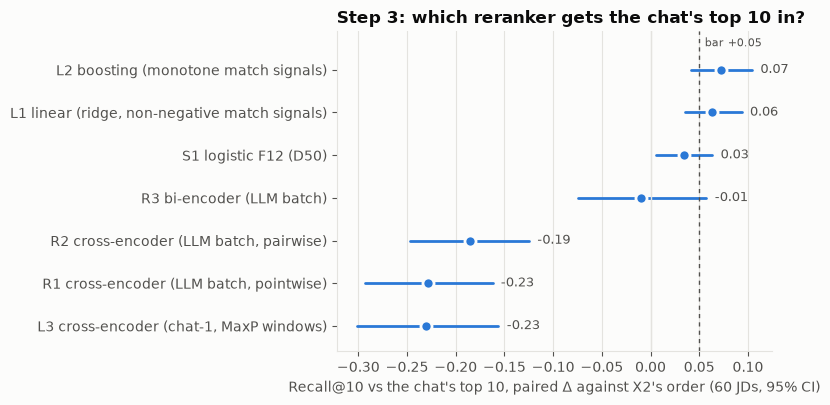

In [6]:
cands = [(n, b["delta_vs_x2"]["recall"]["total"]) for n, b in s3["candidates"].items()
         if b["delta_vs_x2"] and "ablation_of" not in b]
cands.sort(key=lambda nb: nb[1]["value"], reverse=True)
fig, ax = plt.subplots(figsize=(8, 0.45 * len(cands) + 1))
reporting.dot_ci(ax, [n for n, _ in cands], [d["value"] for _, d in cands],
                 [d["ci"][0] for _, d in cands], [d["ci"][1] for _, d in cands],
                 ref=s3["bar"], ref_label="bar +0.05")
ax.axvline(0, color=reporting.GRID, linewidth=1)
ax.set_xlabel("Recall@10 vs the chat's top 10, paired Δ against X2's order (60 JDs, 95% CI)")
ax.set_title("Step 3: which reranker gets the chat's top 10 in?", loc="left")
plt.tight_layout(); plt.show()

### Ablations of the better linear/boosting learner

In [7]:
pd.DataFrame({n: {**{f"R@10 Δ vs full {sc}": fmt(b["delta_vs_full"]["recall"][sc]) for sc in SCOPES},
                  "R@10 Δ vs X2 total": fmt(b["delta_vs_x2"]["recall"]["total"])}
              for n, b in s3["candidates"].items() if "ablation_of" in b}).T

,R@10 Δ vs full generic,R@10 Δ vs full targeted,R@10 Δ vs full total,R@10 Δ vs X2 total
L2 boosting (monotone match signals) without tfidf_scaled,"-0.007 [-0.035, +0.020]","-0.023 [-0.061, +0.014]","-0.012 [-0.035, +0.010]","+0.060 [+0.024, +0.098]"
L2 boosting (monotone match signals) without role_match,"-0.081 [-0.129, -0.035]","-0.049 [-0.114, +0.029]","-0.070 [-0.110, -0.031]","+0.002 [-0.048, +0.055]"
L2 boosting (monotone match signals) without sbert,"-0.033 [-0.058, -0.009]","-0.025 [-0.060, +0.010]","-0.030 [-0.050, -0.011]","+0.042 [+0.014, +0.071]"


In [8]:
pd.Series(s3["l1_standardised_coefficients_mean_over_folds"], name="L1 standardised coefficient (mean of 5 folds)").round(3)

role_match               12.063
experience_compatible     1.016
tfidf_scaled              3.984
coverage                  0.000
coverage_unweighted       0.000
log_matched               3.589
log_jd_concepts          -2.372
log_cv_concepts           1.608
skill_overlap             0.000
exp_gap                  -0.602
exp_known                -0.059
sbert                     6.086
Name: L1 standardised coefficient (mean of 5 folds), dtype: float64

### Human check (exploratory)

The same out-of-fold scores on the judged CVs inside the shortlists: did a model learn the chat's
mistakes? Per-JD AUC on the final label and pairwise agreement with yc's grades, paired against
X2.

In [9]:
rows = {}
for name, b in s3["human_check"]["systems"].items():
    if "auc_delta_vs_x2" not in b:
        continue
    a = {(x["subset"], x["scope"]): x for x in b["auc_delta_vs_x2"]}
    p = {(x["subset"], x["scope"]): x for x in b["pairwise_delta_vs_x2"]}
    ci = lambda x: f"{x['delta']:+.3f} [{x['ci'][0]:+.3f}, {x['ci'][1]:+.3f}]"
    rows[name[:34]] = {"AUC Δ gen / tar": f"{a[('all', 'generic')]['delta']:+.3f} / {a[('all', 'targeted')]['delta']:+.3f}",
                       "AUC Δ total": ci(a[("all", "total")]), "AUC Δ llm_free": f"{a[('llm_free', 'total')]['delta']:+.3f}",
                       "pairwise Δ gen / tar": f"{p[('full', 'generic')]['delta']:+.3f} / {p[('full', 'targeted')]['delta']:+.3f}",
                       "pairwise Δ total": ci(p[("full", "total")]), "pairwise Δ llm_free": f"{p[('llm_free', 'total')]['delta']:+.3f}"}
print(f"{s3['human_check']['judged_pairs']} judged pairs inside the shortlists")
pd.DataFrame(rows).T

422 judged pairs inside the shortlists


,AUC Δ gen / tar,AUC Δ total,AUC Δ llm_free,pairwise Δ gen / tar,pairwise Δ total,pairwise Δ llm_free
S1 logistic F12 (D50),+0.073 / -0.004,"+0.044 [-0.030, +0.117]",+0.036,+0.055 / +0.080,"+0.063 [+0.005, +0.120]",+0.071
"R1 cross-encoder (LLM batch, point",-0.040 / +0.010,"-0.021 [-0.155, +0.119]",-0.095,+0.036 / -0.032,"+0.014 [-0.072, +0.103]",+0.058
"R2 cross-encoder (LLM batch, pairw",-0.032 / -0.029,"-0.031 [-0.153, +0.092]",-0.152,+0.052 / -0.068,"+0.013 [-0.073, +0.099]",+0.042
R3 bi-encoder (LLM batch),+0.106 / +0.066,"+0.091 [-0.022, +0.206]",+0.008,+0.114 / -0.028,"+0.068 [-0.019, +0.158]",+0.088
"L1 linear (ridge, non-negative mat",+0.076 / +0.062,"+0.071 [+0.005, +0.145]",+0.058,+0.095 / +0.108,"+0.100 [+0.048, +0.158]",+0.104
L2 boosting (monotone match signal,+0.095 / +0.161,"+0.120 [+0.055, +0.195]",+0.111,+0.103 / +0.134,"+0.113 [+0.062, +0.173]",+0.133
"L3 cross-encoder (chat-1, MaxP win",-0.086 / +0.050,"-0.035 [-0.158, +0.092]",-0.108,+0.010 / -0.038,"-0.006 [-0.101, +0.094]",+0.025


## 4 · End to end: stage 1 → stage 2 → top 10

In [10]:
rows = {}
for label, b in s3["end_to_end"].items():
    r = b["summary"]["recall"]
    row = {"R@10 gen / tar": f"{r['generic']['value']:.3f} / {r['targeted']['value']:.3f}",
           "R@10 total": val(r["total"]), "nDCG@10": f"{b['summary']['ndcg']['total']['value']:.3f}",
           "No Fits": f"{b['summary']['no_fits']['total']['value']:.2f}",
           "JDs < 10": b["returned_per_jd"]["jds_under_10"], "judged Fits": b["judged_fits_in_top10_total"]}
    if "delta_vs_x2_alone" in b:
        row["Δ vs X2 alone"] = fmt(b["delta_vs_x2_alone"]["recall"]["total"])
    rows[label] = row
pd.DataFrame(rows).T

,R@10 gen / tar,R@10 total,nDCG@10,No Fits,JDs < 10,judged Fits,Δ vs X2 alone
X2 alone,0.421 / 0.416,"0.419 [0.366, 0.471]",0.776,1.70,0,116,NaN
"S1 alone (passed set, by probability)",0.438 / 0.389,"0.422 [0.368, 0.475]",0.753,0.75,14,118,"+0.003 [-0.033, +0.038]"
X2 top 100 -> L2,0.502 / 0.472,"0.492 [0.445, 0.536]",0.824,1.35,0,113,"+0.072 [+0.042, +0.104]"
S1 passed set -> L2,0.470 / 0.406,"0.449 [0.395, 0.502]",0.757,0.72,14,110,"+0.030 [-0.010, +0.071]"


### L3's training, per fold

In [11]:
costs = json.load(open(OUTPUT / "rerank" / "chat-rerank-costs.json"))
replies = pd.read_csv(OUTPUT / "rerank" / "chat-rerank-replies.csv").drop_duplicates(["jd_id", "short_id"], keep="last")
print(f"target variance, score / 100 over X2's top 100: {(replies[replies.batch <= 5].score / 100).var():.3f}")
pd.DataFrame(costs["l3_folds"]).set_index("fold")[["pairs", "windows", "epoch_loss", "train_seconds", "score_seconds"]]

target variance, score / 100 over X2's top 100: 0.072


,pairs,windows,epoch_loss,train_seconds,score_seconds
fold,,,,,
0,4800,10124,[0.066877],7471.6,318.9
1,4800,9985,[0.065165],7347.6,353.2
2,4800,10085,[0.070801],6722.7,324.6
3,4800,10117,[0.069933],6752.1,303.3
4,4800,10117,[0.067164],5007.5,185.7


## 5 · Findings

1. **Step 1: the classifier passes.** On the final set, F12's per-JD AUC is +0.009 [−0.013, 0.031]
   against X2; size-matched recall on the pools is −0.007 [−0.040, 0.027]. `role_match` stays the
   largest standardised coefficient. At P ≥ 0.5 it passes a median of 23 CVs per JD, and those
   keep 240 of the 367 judged Fits (X2's top 100 keeps 332).
2. **Step 2 passes on the passed set** (overlap 0.987 with X2's top 100); S1's own top 100 would
   not (0.691).
3. **Step 3: L2 passes the bar and is the best reranker.** Recall@10 against the chat's top 10
   rises from 0.419 (X2's order) to 0.492, +0.072 [+0.042, +0.104] (generic +0.081, targeted
   +0.056). L1 passes too (+0.064 [+0.035, +0.094]). The classifier's probability alone gains
   +0.034 [+0.005, +0.063], under the bar. Chat No Fits in the top 10 fall from 1.70 to 1.35.
4. **The gain comes from role.** Without `role_match`, L2 is level with X2 (+0.002); without
   `sbert` it keeps +0.042; without `tfidf_scaled`, +0.060.
5. **Every text model loses.** R1 and R2 (cross-encoders trained on D50) and L3 (trained on
   `chat-1`) are 0.19 to 0.23 below X2; R3 is level (−0.010). L3 hardly learned at its fixed
   defaults: one epoch, training MSE 0.065 to 0.071 per fold on a target whose variance is 0.072.
6. **Human check (exploratory): L2 did not just learn the chat's mistakes.** On the 422 judged CVs
   inside the shortlists, L2 beats X2 on per-JD AUC by +0.116 [+0.043, +0.198] and on pairwise
   agreement with yc's grades by +0.127 [+0.064, +0.193] (55 JDs).
7. **End to end, the short passed set costs recall.** S1's passed set → L2 reaches 0.449: +0.030
   [−0.010, +0.071] over X2 alone, but −0.043 [−0.070, −0.018] under X2's top 100 → L2 (0.492),
   because 14 JDs pass fewer than 10 CVs. It shows fewer chat No Fits (0.72 against 1.35), mostly
   because it shows fewer CVs. Stage 1's threshold (step 4) is the lever.

## Limitations

- `chat-1` was run once. Its batch drift (+3.6 in batch 1 to −3.7 in batch 5) and its
  multiples-of-5 scores cap every model's Recall@10 below 1; there is no noise ceiling (accepted,
  owner 18 Oct 2026).
- `chat-1` is the reference for the stage-2 task only (D61). The human check is exploratory.
- The best reranker is picked on the same out-of-fold Recall@10 it is reported with: mildly
  optimistic.
- R1/R2 cut a pair at 384 tokens (90% of `chat-1` pairs lose text); L3 reads every CV token but
  cuts JDs at 192 tokens (50 of 60 JDs are longer).
- The 20-pair extension was scored later, as batch 6 of each JD's chat.